# V0 - ResNet on three-channel CIFAR-10 with validation
Use a stratified validation subset to monitor training and select the best epoch.
Select the color space and matching PNG directory in CONFIG.
Normalization statistics are computed only on the training subset and cached.
Start with a fresh kernel. Initialize once, then rerun training to add epochs.


In [1]:
from pathlib import Path
import json
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
# Experiment choices; preserve the selected checkpoint and current defaults.
CONFIG = {
    "checkpoint_name": None,  # Specify folder of the specific model and the name (last.pth, best_loss.pth or best_acc.pth). None starts a new experiment.
    "batch_size": 32,
    "model": "CustomResNet18",  # CustomResNet18 or CustomResNet50.
    "model_seed": 42,
    "loader_seed": 2,
    "split_seed": 42,
    "validation_fraction": 0.1,
    "num_classes": 10,
    "data_dir": "data/cifar-10_resized",
    "color_space": "RGB",  # RGB, YCbCr or YCoCgR; select the matching PNG folder.
    "force_recompute_stats": False,
    "train_manifest": "output/manifest_train.json",
    "test_manifest": "output/manifest_test.json",
    "models_dir": "output/models",
}

CONFIG_NET = {
    "learning_rate": 0.01,
    "min_lr": 1e-5,
    "momentum": 0,
    "weight_decay": 0,
    "use_scheduler": True,
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
}

torch.manual_seed(CONFIG["model_seed"])
CHECKPOINT_NAME = CONFIG["checkpoint_name"]
# Local: run from root or notebooks/. In Colab mount Drive first and set
# PROJECT_ROOT to the folder containing data/, output/ and src/ml_setup/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
import sys
SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))
DATA_ROOT = PROJECT_ROOT / CONFIG["data_dir"]
TRAIN_MANIFEST = PROJECT_ROOT / CONFIG["train_manifest"]
TEST_MANIFEST = PROJECT_ROOT / CONFIG["test_manifest"]
MODELS_DIR = PROJECT_ROOT / CONFIG["models_dir"]
CHECKPOINT_TO_LOAD = MODELS_DIR / CHECKPOINT_NAME if CHECKPOINT_NAME else None
VERSION = "v0"
REPRESENTATION = f"uncompressed-{CONFIG['color_space'].lower()}-png-v0"
print("Device:",device, "\nDataset path:",DATA_ROOT)
import hashlib
import random
from collections import Counter

EXPERIMENT = {"version": VERSION, "representation": REPRESENTATION, "scale": None}
SPLIT_PATH = PROJECT_ROOT / "output" / "splits" / (
    f"cifar10_train_val_{CONFIG['validation_fraction']:g}.json"
)


Device: cuda 
Dataset path: C:\Users\Edward\Desktop\AARHUS\data\cifar-10_resized


In [2]:
# Network parameters; channel statistics are prepared after the split.
BATCH_SIZE = CONFIG["batch_size"]
INITIAL_LR = CONFIG_NET["learning_rate"]


## Dataset and preprocessing
Reuse the manifests as label tables, mapping `.network.npz` names to `.png`.
PNG files must have three uint8 channels and size 224 x 224.
YCoCgR files store Y, biased Co and biased Cg in PNG R/G/B slots; do not convert
these values to RGB before normalization. Training alone uses horizontal flips.


In [3]:

def make_or_load_split(manifest_path, split_path, fraction, seed):
    """"Split the training set into training and validation"""
    if not 0 < fraction < 1:
        raise ValueError("validation_fraction must be between 0 and 1")
    
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

    if manifest.get("split") != "train":
        raise ValueError("Split must be created from the official training manifest")
    
    records = {}
    for sample in manifest["samples"]:
        name = sample["file"]
        image_id = Path(name).stem
        if image_id in records:
            raise ValueError("Duplicate image ID")
        records[image_id] = sample["label"]
    identity = {"schema": "cifar10-stratified-v1", 
                "seed": seed,
                "validation_fraction": fraction, 
                "class_to_idx": manifest["class_to_idx"]}
    if split_path.exists():
        split = json.loads(split_path.read_text(encoding="utf-8"))
        if any(split.get(k) != v for k, v in identity.items()):
            raise ValueError("Saved split differs from dataset/configuration; do not overwrite it")
    else:
        rng = random.Random(seed)
        train_ids, val_ids = [], []
        for label in sorted(set(records.values())):
            """Take 10% of the data, for each class (label) that appears"""
            ids = sorted(i for i, y in records.items() if y == label)
            n_val = int(len(ids) * fraction + 0.5)
            rng.shuffle(ids)
            val_ids.extend(ids[:n_val])
            train_ids.extend(ids[n_val:])
        split = {**identity, "train_ids": sorted(train_ids), "val_ids": sorted(val_ids)}
        split_path.parent.mkdir(parents=True, exist_ok=True)
        with split_path.open("x", encoding="utf-8") as f:
            json.dump(split, f, indent=2)
    a, b = split["train_ids"], split["val_ids"]

    if (len(a) != len(set(a)) or len(b) != len(set(b))
            or set(a) & set(b) or set(a) | set(b) != set(records)):
        raise ValueError("Saved split must partition all training IDs exactly once")
    if not a or not b:
        raise ValueError("Training and validation subsets must be nonempty")
    for label in sorted(set(records.values())):
        total = sum(y == label for y in records.values())
        if sum(records[i] == label for i in b) != int(total * fraction + 0.5):
            raise ValueError("Saved partition is not stratified as configured")
    return split

split_for_validation = make_or_load_split(
    TRAIN_MANIFEST, SPLIT_PATH, CONFIG["validation_fraction"], CONFIG["split_seed"]
)
train_ids = split_for_validation["train_ids"]
val_ids = split_for_validation["val_ids"]
#SPLIT_SHA256 = digest(split_for_validation)
print("Split:", SPLIT_PATH)


Split: C:\Users\Edward\Desktop\AARHUS\output\splits\cifar10_train_val_0.1.json


## Training-only channel statistics
Compute one mean and population standard deviation per stored channel on train_ids,
after division by 255 and before augmentation. Validation and test use the same values.
Matching cached statistics are loaded automatically; a changed dataset or split triggers
recomputation. Set force_recompute_stats=True to refresh explicitly. Keep PNGs unchanged
during training; cache identity uses filenames, sizes and modification timestamps.
For RGB runs, these dataset statistics replace the previous ImageNet constants.


In [4]:
import numpy as np

STATS_PATH = PROJECT_ROOT / "output" / "normalization" / (
    f"v0_{DATA_ROOT.name}_train_with_validation.json"
)

def load_or_compute_channel_stats(manifest_path, image_root, selected_ids,
                                  cache_path, color_space, force=False):
    """Compute population statistics on training pixels before augmentation."""
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("split") != "train":
        raise ValueError("Statistics require the official training manifest")
    wanted = set(selected_ids)
    rows = [s for s in manifest["samples"] if Path(s["file"]).stem in wanted]
    if not rows or len(rows) != len(wanted):
        raise ValueError("Missing or duplicate training samples")
    paths = sorted(image_root / (s["file"].removesuffix(".network.npz") + ".png")
                   for s in rows)
    inventory = [(p.name, p.stat().st_size, p.stat().st_mtime_ns) for p in paths]
    context = {
        "schema": "v0-channel-statistics-v1", "color_space": color_space,
        "image_root": str(image_root.resolve()),
        "training_ids_sha256": hashlib.sha256(
            json.dumps(sorted(wanted)).encode()).hexdigest(),
        "inventory_sha256": hashlib.sha256(json.dumps(inventory).encode()).hexdigest(),
        "units": "stored uint8 channels / 255", "ddof": 0,
    }
    def valid_stats(stats):
        mean = np.asarray(stats.get("mean", []), dtype=np.float64)
        std = np.asarray(stats.get("std", []), dtype=np.float64)
        return (mean.shape == (3,) and std.shape == (3,)
                and np.isfinite(mean).all() and np.isfinite(std).all()
                and (std > 0).all())

    if cache_path.exists() and not force:
        cached = json.loads(cache_path.read_text(encoding="utf-8"))
        if cached.get("context") == context and valid_stats(cached):
            print("Loaded channel statistics:", cache_path)
            return cached
        print("Statistics cache does not match this training dataset; recomputing.")

    # Merge per-image moments in float64 without loading the dataset into memory.
    count = 0
    mean = np.zeros(3, dtype=np.float64)
    m2 = np.zeros(3, dtype=np.float64)
    for index, path in enumerate(paths, 1):
        with Image.open(path) as image:
            if image.mode != "RGB" or image.size != (224, 224):
                raise ValueError(f"Expected a three-channel 224 x 224 PNG: {path}")
            pixels = np.asarray(image, dtype=np.float64).reshape(-1, 3) / 255.0
        n = len(pixels)
        image_mean = pixels.mean(axis=0)
        delta = image_mean - mean
        total = count + n
        m2 += ((pixels - image_mean) ** 2).sum(axis=0) + delta ** 2 * count * n / total
        mean += delta * n / total
        count = total
        if index % 1000 == 0 or index == len(paths):
            print(f"Channel statistics: {index}/{len(paths)} images")
    result = {"source": "training_subset", "context": context,
              "num_images": len(paths), "pixels_per_channel": count,
              "mean": mean.tolist(), "std": np.sqrt(m2 / count).tolist()}
    if not valid_stats(result):
        raise ValueError("Invalid channel statistics: standard deviations must be positive")
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    temporary = cache_path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(result, indent=2), encoding="utf-8")
    temporary.replace(cache_path)
    print("Saved channel statistics:", cache_path)
    return result

normalization_stats = load_or_compute_channel_stats(
    TRAIN_MANIFEST, DATA_ROOT / "train", train_ids, STATS_PATH,
    CONFIG["color_space"], force=CONFIG["force_recompute_stats"]
)
CHANNEL_MEAN = normalization_stats["mean"]
CHANNEL_STD = normalization_stats["std"]
print("Channel mean:", CHANNEL_MEAN)
print("Channel standard deviation:", CHANNEL_STD)


Loaded channel statistics: C:\Users\Edward\Desktop\AARHUS\output\normalization\v0_cifar-10_resized_train_with_validation.json
Channel mean: [0.49135083843953903, 0.48206815197780867, 0.44654978128404865]
Channel standard deviation: [0.24135677651869158, 0.23794373325777843, 0.2565584094495892]


In [5]:
class RGBDataset(Dataset):
    def __init__(self, manifest_path, image_root, split, transform, selected_ids=None):
        self.manifest_path = Path(manifest_path)
        self.image_root = Path(image_root)
        self.transform = transform

        # The hash identifies the label table when resuming a checkpoint.
        raw = self.manifest_path.read_bytes()
        manifest = json.loads(raw)

        if manifest.get("split") != split:
            raise ValueError("Manifest split does not match the requested split")
        if selected_ids is not None:
            wanted = set(selected_ids)
            rows = [row for row in manifest["samples"] if Path(row["file"]).stem in wanted]
            if len(rows) != len(wanted):
                raise ValueError("Missing or duplicate selected image IDs")
            manifest["samples"] = rows
        if not manifest["samples"]:
            raise ValueError("Empty dataset")
        self.idx_to_class = {index: name for name, index in manifest['class_to_idx'].items()}

        # Existing manifests list NPZs; the RGB files have the same image IDs.
        self.samples = [
            dict(file=row['file'].removesuffix('.network.npz') + '.png', label=row['label'])
            for row in manifest['samples']
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        row = self.samples[index]
        with Image.open(self.image_root / row['file']) as image:
            if image.mode != "RGB" or image.size != (224, 224):
                raise ValueError("Expected an RGB PNG with size 224 x 224")
            image = self.transform(image)
        return image, torch.tensor(row['label'], dtype=torch.long)

train_transform = transforms.Compose([
    transforms.ToTensor(), transforms.RandomHorizontalFlip(p=0.5),
    transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
train_data = RGBDataset(TRAIN_MANIFEST, DATA_ROOT / 'train', 'train', train_transform, train_ids)
val_data = RGBDataset(TRAIN_MANIFEST, DATA_ROOT / 'train', 'train', test_transform, val_ids)
test_data = RGBDataset(TEST_MANIFEST, DATA_ROOT / 'test', 'test', test_transform)
# Both splits must interpret class indices in the same way.
if train_data.idx_to_class != test_data.idx_to_class:
    raise ValueError("Train/test class mappings differ")

data_context = dict(image_size=[3, 224, 224], batch_size=BATCH_SIZE,
                    augmentation="horizontal_flip_p0.5", conv1="random_trainable",
                    backbone="ImageNet1K_V1", batchnorm="running_statistics_frozen",
                    model=CONFIG["model"], freeze_backbone=False, freeze_batchnorm=True,
                    normalization=normalization_stats)
print(f"Training: {len(train_data)}; test: {len(test_data)}")
print(f"Validation: {len(val_data)}")
print("Validation per class:", dict(sorted(Counter(s["label"] for s in val_data.samples).items())))


Training: 45000; test: 10000
Validation: 5000
Validation per class: {0: 500, 1: 500, 2: 500, 3: 500, 4: 500, 5: 500, 6: 500, 7: 500, 8: 500, 9: 500}


In [6]:
train_generator = torch.Generator().manual_seed(CONFIG["loader_seed"])
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train: {len(train_loader)} batches; test: {len(test_loader)} batches")
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Validation: {len(val_loader)} batches")


Train: 1407 batches; test: 313 batches
Validation: 157 batches


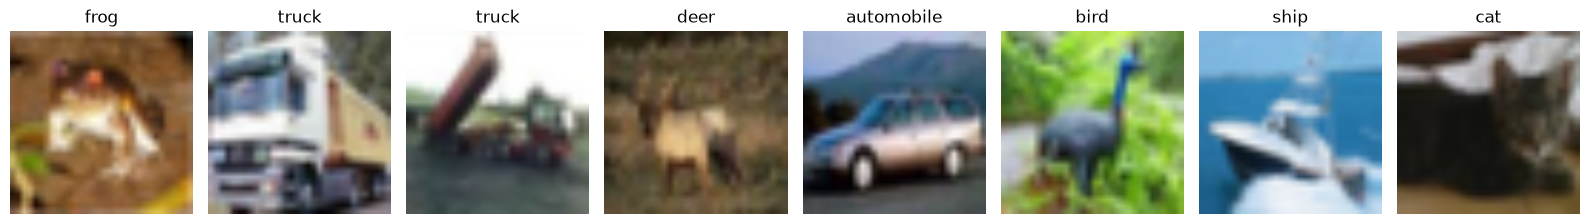

In [7]:
# Preview without consuming training-loader or augmentation RNG state.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(123)
    previews = [train_data[i] for i in range(8)]
images = torch.stack([item[0] for item in previews])
labels = torch.stack([item[1] for item in previews])
assert images.shape == (8, 3, 224, 224) and torch.isfinite(images).all()
mean = torch.tensor(CHANNEL_MEAN).view(3, 1, 1)
std = torch.tensor(CHANNEL_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, image, label in zip(axes, images, labels):
    ax.imshow((image * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(train_data.idx_to_class[label.item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

## Model and BatchNorm
Select CustomResNet18 or CustomResNet50 in CONFIG (ResNet18 remains the default).
All model parameters are trainable, including BatchNorm affine parameters.
BatchNorm running statistics stay frozen through freeze_batchnorm=True.
The RGB/YCbCr/YCoCgR inputs retain three channels. conv1 and fc are randomly
initialized; the remaining initial weights come from ImageNet V1.


In [9]:
# Run once for a new experiment OR to restore a checkpoint.
# Do not rerun this cell when merely adding epochs in the current session.

import math
import torch.nn as nn
import ml_setup.models 

# load checkpoint (if any) and define the model
checkpoint = None 
if CHECKPOINT_TO_LOAD is not None:
    checkpoint = torch.load(CHECKPOINT_TO_LOAD, map_location="cpu", weights_only=True)
    if checkpoint.get("schema") != "resnet-validation-v1":
        raise ValueError("Checkpoint missing validation split or using a different split")
    if checkpoint.get("version") != VERSION or checkpoint.get("representation") != REPRESENTATION:
        raise ValueError("Checkpoint version/representation differs (legacy checkpoints need explicit migration).")
    if checkpoint.get("scale") != EXPERIMENT["scale"]:
        raise ValueError("Checkpoint scale differs from the selected experiment.")

MODEL = CONFIG["model"]
model_classes = {"CustomResNet18": ml_setup.models.CustomResNet18,
                 "CustomResNet50": ml_setup.models.CustomResNet50}
if MODEL not in model_classes:
    raise ValueError("Select CustomResNet18 or CustomResNet50")
torch.manual_seed(CONFIG["model_seed"])
model = model_classes[MODEL](
    num_classes=CONFIG["num_classes"], pretrained=checkpoint is None,
    in_channels=3, freeze_backbone=False, freeze_batchnorm=True
).to(device)

# LR, loss, optimizer and scheduler setup
INITIAL_LR = CONFIG_NET["learning_rate"]
torch.manual_seed(CONFIG["model_seed"])

loss_fn = nn.CrossEntropyLoss()

# comment out for simple optimizer
#optimizer = torch.optim.SGD(
#    (p for p in model.parameters() if p.requires_grad), lr=INITIAL_LR
#)

optimizer = torch.optim.SGD(
    (p for p in model.parameters() if p.requires_grad),
    lr=INITIAL_LR,
    momentum=CONFIG_NET["momentum"],
    weight_decay=CONFIG_NET["weight_decay"]
)
scheduler = None
if CONFIG_NET["use_scheduler"]:
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=CONFIG_NET["scheduler_factor"],
        patience=CONFIG_NET["scheduler_patience"],
        min_lr=CONFIG_NET["min_lr"],
        threshold=1e-4,
        threshold_mode="rel",
        cooldown=0,
    )


history = []
test_metrics = None
if checkpoint is not None:
    if checkpoint.get("split_info") != split_for_validation:
        raise ValueError("Checkpoint validation split differs")
    if checkpoint.get("completed_epochs") != len(checkpoint["history"]):
        raise ValueError("Checkpoint epoch count and history disagree")
    saved_context = checkpoint.get("data_context")
    if saved_context is not None and saved_context != data_context:
        raise ValueError("Checkpoint data/model protocol differs")
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if scheduler is not None:
        saved_scheduler_state = checkpoint.get("scheduler_state_dict")
        if saved_scheduler_state is not None:
            scheduler.load_state_dict(saved_scheduler_state)
        else:
            print("No saved scheduler state; starting a new scheduler.")
    history = checkpoint["history"]
    test_metrics = checkpoint.get("test_metrics")

best_val_loss = checkpoint["best_val_loss"] if checkpoint else float("inf")
best_epoch = checkpoint["best_epoch"] if checkpoint else None
best_model_state = checkpoint["best_model_state_dict"] if checkpoint else None

# Legacy checkpoints do not contain the historical best-accuracy weights.
best_val_accuracy = float("-inf")
best_acc_epoch = None
best_acc_model_state = None
if checkpoint is not None:
    best_acc_model_state = checkpoint.get("best_acc_model_state_dict")
    if best_acc_model_state is not None:
        best_val_accuracy = checkpoint["best_val_accuracy"]
        best_acc_epoch = checkpoint["best_acc_epoch"]
    else:
        # Recover the best accuracy among the weights actually available.
        candidates = [(len(history), checkpoint["model_state_dict"]),
                      (best_epoch, best_model_state)]
        for candidate_epoch, candidate_state in candidates:
            row = next((r for r in history if r["epoch"] == candidate_epoch), None)
            if row is not None and candidate_state is not None and row["val_accuracy"] > best_val_accuracy:
                best_val_accuracy = float(row["val_accuracy"])
                best_acc_epoch = candidate_epoch
                best_acc_model_state = {k: v.detach().cpu().clone() for k, v in candidate_state.items()}
        print("Legacy checkpoint: best accuracy initialized from available weights only; "
              "other historical epochs cannot be recovered.")


model.eval()

if checkpoint is not None:
    torch.set_rng_state(checkpoint["torch_rng_state"])
    train_generator.set_state(checkpoint["loader_rng_state"])
    if torch.cuda.is_available() and checkpoint.get("cuda_rng_states"):
        if len(checkpoint["cuda_rng_states"]) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])


# check integrity of the checkpoint and the model
print("Completed epochs:", len(history))
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Model ready. Run the single training cell below to add epochs.")


from datetime import datetime
from copy import deepcopy

# Resume in the existing experiment; new experiments get unique directories.
if CHECKPOINT_TO_LOAD is not None:
    RUN_DIR = CHECKPOINT_TO_LOAD.parent
else:
    scheduler_suffix = "_LRO" if scheduler is not None else ""
    RUN_DIR = MODELS_DIR / MODEL / (
        f"v0_{CONFIG['color_space']}{scheduler_suffix}_{datetime.now():%Y%m%d}"
    )
    RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Checkpoints:", RUN_DIR)


Completed epochs: 0
Total parameters: 11181642
Trainable parameters: 11181642
Model ready. Run the single training cell below to add epochs.
Checkpoints: C:\Users\Edward\Desktop\AARHUS\output\models\CustomResNet18\v0_RGB_LRO_20261110


In [11]:
import numpy as np

from ml_setup.helper_functions import train_step, test_step, summarize_training_time


def macro_f1_from_counts(counts):
    """Return macro-F1 in percent; undefined per-class F1 is zero."""
    counts = np.asarray(counts, dtype=np.float64)
    denominator = counts.sum(axis=0) + counts.sum(axis=1)
    scores = np.divide(2 * np.diag(counts), denominator,
                       out=np.zeros(counts.shape[0]), where=denominator != 0)
    return float(100 * scores.mean())


def save_checkpoint(filename):
    if not history:
        raise ValueError("No completed epoch to save")
    model_metrics = dict(history[-1])
    payload = {
        "data_context": data_context,
        "config": CONFIG.copy(), "config_net": CONFIG_NET.copy(),
        "model_metrics": model_metrics,
        "val_loss": model_metrics["val_loss"],
        "val_accuracy": model_metrics["val_accuracy"],
        "schema": "resnet-validation-v1", **EXPERIMENT,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_enabled": scheduler is not None,
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "num_classes": CONFIG["num_classes"], "completed_epochs": len(history),
        "history": history, "normalization": normalization_stats,
        "idx_to_class": train_data.idx_to_class,
        "split_info": split_for_validation,
        "best_val_loss": best_val_loss, 
        "best_epoch": best_epoch,  # Legacy alias for best_loss_epoch.
        "best_loss_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "best_acc_epoch": best_acc_epoch,
        "best_acc_model_state_dict": best_acc_model_state,
        "checkpoint_kind": {"best_loss.pth": "best_loss", "best_acc.pth": "best_acc"}.get(filename, "last"),
        "model_epoch": history[-1]["epoch"] if history else 0,
        "best_model_state_dict": best_model_state,
        "test_metrics": test_metrics,
        "training_time": summarize_training_time(history),
        "torch_rng_state": torch.get_rng_state(),
        "loader_rng_state": train_generator.get_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    }
    destination = RUN_DIR / filename
    temporary = destination.with_suffix(".pth.partial")
    torch.save(payload, temporary)
    temporary.replace(destination)


## Training and validation
Each execution adds epochs using the shared train_step and test_step helpers.
Record the same loss, accuracy, validation macro-F1 (percent), timing and LR fields
as the compressed experiment. ReduceLROnPlateau steps on validation loss after each
epoch; history records the LR used before that step. Save best_loss.pth, best_acc.pth
and last.pth, with metrics for the epoch represented by each file's model weights.
Strict comparisons retain the earliest epoch on ties.


In [12]:
NEW_LR = None  # Optional positive value; None preserves optimizer LR.
if NEW_LR is not None:
    if not math.isfinite(NEW_LR) or NEW_LR <= 0:
        raise ValueError("NEW_LR must be finite and positive")
    for group in optimizer.param_groups:
        group['lr'] = NEW_LR
print('Current learning rates:', [group['lr'] for group in optimizer.param_groups])

Current learning rates: [0.01]


In [13]:
from tqdm.auto import tqdm
from timeit import default_timer as timer

ADDITIONAL_EPOCHS = 20
if not isinstance(ADDITIONAL_EPOCHS, int) or ADDITIONAL_EPOCHS < 1:
    raise ValueError("ADDITIONAL_EPOCHS must be positive")

start_epoch = len(history)
end_epoch = start_epoch + ADDITIONAL_EPOCHS

start_time = timer()
test_metrics = None

for epoch in tqdm(range(start_epoch + 1, end_epoch + 1)):
    print(f"\nEpoch {epoch}/{end_epoch}")
    metrics = train_step(model, train_loader, loss_fn, optimizer, device)
    print("Validation (the shared helper labels this evaluation 'Test'):")
    val_metrics = test_step(model, val_loader, loss_fn, device,
                            num_classes=CONFIG["num_classes"])   
    if not math.isfinite(val_metrics["loss"]):
        raise ValueError("Non-finite validation loss")
    
    history.append({"epoch": epoch, "loss": float(metrics["loss"]),
                    "accuracy": float(metrics["accuracy"]),
                    "val_loss": float(val_metrics["loss"]),
                    "val_accuracy": float(val_metrics["accuracy"]),
                    "val_macro_f1": macro_f1_from_counts(val_metrics["confusion_counts"]),
                    "validation_seconds": val_metrics["evaluation_seconds"],
                    "lr": float(optimizer.param_groups[0]["lr"]),
                    "training_seconds": metrics["training_seconds"],
                    "training_device": str(device)})
    
    # History records the LR used in this epoch; step sets the next epoch's LR.
    if scheduler is not None:
        previous_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val_metrics["loss"])
        new_lr = optimizer.param_groups[0]["lr"]
        if new_lr != previous_lr:
            print(f"Learning rate reduced: {previous_lr:g} -> {new_lr:g}")

    # Strict comparisons keep the earliest epoch when metrics tie
    improved_loss = val_metrics["loss"] < best_val_loss
    improved_acc = val_metrics["accuracy"] > best_val_accuracy
    if improved_loss or improved_acc:
        current_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if improved_loss:
        best_val_loss = float(val_metrics["loss"])
        best_epoch = epoch
        best_model_state = current_state
    if improved_acc:
        best_val_accuracy = float(val_metrics["accuracy"])
        best_acc_epoch = epoch
        best_acc_model_state = current_state

    if improved_loss:
        save_checkpoint("best_loss.pth")
        print(f"New best validation loss: {best_val_loss:.5f} (epoch {best_epoch})")
    if improved_acc:
        save_checkpoint("best_acc.pth")
        print(f"New best validation accuracy: {best_val_accuracy:.2f}% (epoch {best_acc_epoch})")
        
    print(f"Validation macro-F1: {history[-1]['val_macro_f1']:.2f}%")
    save_checkpoint("last.pth")

print(f"\nCompleted: {len(history)} epochs; elapsed: {timer() - start_time:.1f}s")
print("Best loss epoch:", best_epoch)
print("Best accuracy epoch:", best_acc_epoch)
print("Resume with checkpoint_name =", str((RUN_DIR / "last.pth").relative_to(MODELS_DIR)))


  0%|          | 0/20 [00:00<?, ?it/s]


Epoch 1/20
Train loss: 1.75678 | Train accuracy: 35.30%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 2.05003 | Test accuracy: 26.40%
New best validation loss: 2.05003 (epoch 1)
New best validation accuracy: 26.40% (epoch 1)
Validation macro-F1: 23.91%

Epoch 2/20
Train loss: 0.73827 | Train accuracy: 74.55%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 1.39678 | Test accuracy: 60.68%
New best validation loss: 1.39678 (epoch 2)
New best validation accuracy: 60.68% (epoch 2)
Validation macro-F1: 60.69%

Epoch 3/20
Train loss: 0.40549 | Train accuracy: 86.06%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.60260 | Test accuracy: 80.02%
New best validation loss: 0.60260 (epoch 3)
New best validation accuracy: 80.02% (epoch 3)
Validation macro-F1: 80.22%

Epoch 4/20
Train loss: 0.29378 | Train accuracy: 89.90%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.30303 | Test accuracy: 89

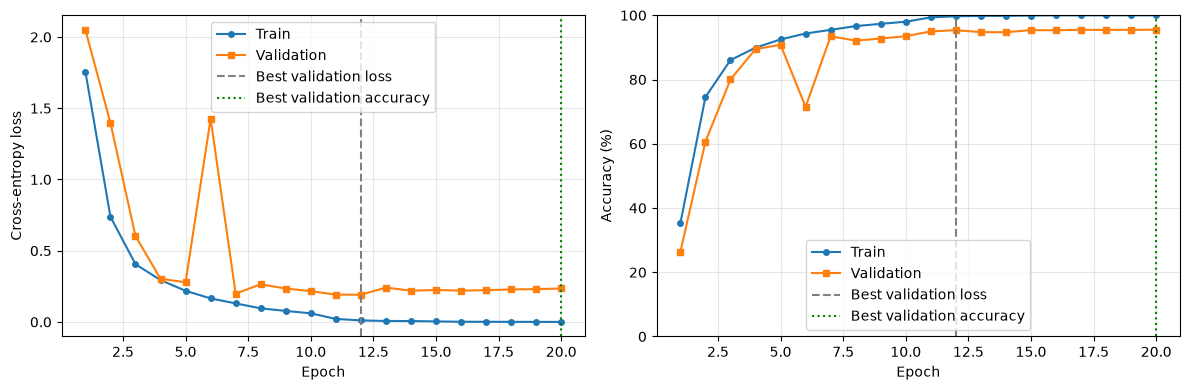

In [14]:
if not history:
    raise ValueError("Train or load a validation checkpoint first")
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ("loss", "accuracy"), ("Cross-entropy loss", "Accuracy (%)")):
    ax.plot(epochs, [r[key] for r in history], label="Train", marker="o", markersize=4)
    ax.plot(epochs, [r["val_" + key] for r in history], label="Validation", marker="s", markersize=4)
    if best_epoch is not None:
        ax.axvline(best_epoch, linestyle="--", color="gray", label="Best validation loss")
    if best_acc_epoch is not None:
        ax.axvline(best_acc_epoch, linestyle=":", color="green", label="Best validation accuracy")
    ax.set(xlabel="Epoch", ylabel=title)
    ax.grid(alpha=0.3)
    ax.legend()
axes[1].set_ylim(0, 100)
fig.tight_layout()
plt.show()


## Final held-out test evaluation
Select best_loss, best_acc or last without changing the training model.


best_acc model (epoch 20) evaluation on test set:
Validation loss: 0.23480 | accuracy: 95.50%
Test loss: 0.27476 | Test accuracy: 94.86%


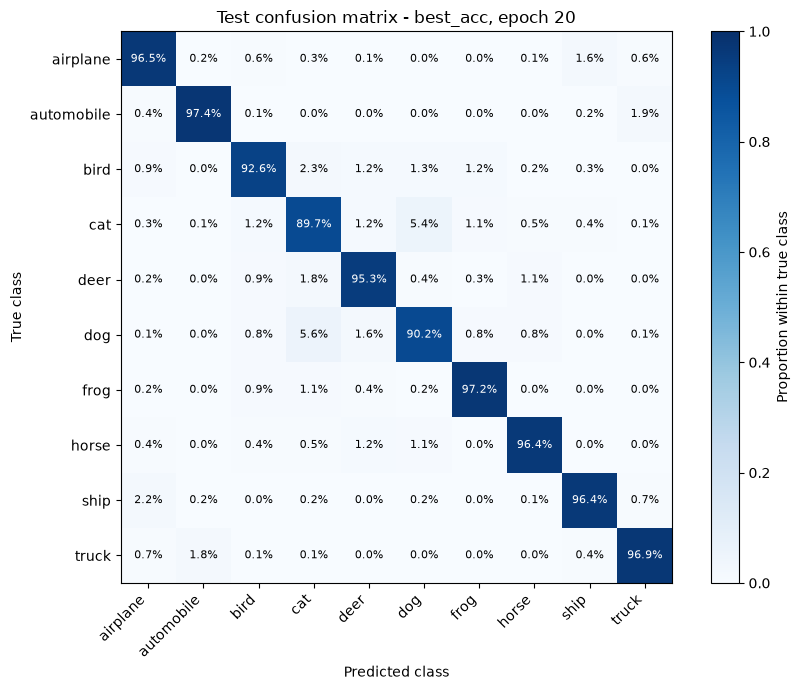

In [17]:
# Select "best_loss", "best_acc" or "last" without changing the training model.
EVALUATE = "best_acc"
choices = {
    "best_loss": (best_epoch, best_model_state),
    "best_acc": (best_acc_epoch, best_acc_model_state),
    "last": (history[-1]["epoch"] if history else None, model.state_dict()),
}
if EVALUATE not in choices:
    raise ValueError("EVALUATE must be best_loss, best_acc or last")
evaluation_epoch, evaluation_state = choices[EVALUATE]
if evaluation_epoch is None or evaluation_state is None:
    raise ValueError("No weights available for the selected evaluation")
evaluation_model = deepcopy(model).cpu()
evaluation_model.load_state_dict(evaluation_state)
evaluation_model.to(device)
# Rows = true classes, columns = predicted classes. Each supported row sums to 1.
import numpy as np

num_classes = CONFIG["num_classes"]
class_names = [test_data.idx_to_class[i] for i in range(num_classes)]

print(f"{EVALUATE} model (epoch {evaluation_epoch}) evaluation on test set:")
evaluation_row = next(r for r in history if r["epoch"] == evaluation_epoch)
print(f"Validation loss: {evaluation_row['val_loss']:.5f} | accuracy: {evaluation_row['val_accuracy']:.2f}%")

evaluation = test_step(evaluation_model, test_loader, loss_fn, device,
                       num_classes=num_classes)

confusion_counts = np.asarray(evaluation["confusion_counts"], dtype=np.int64)
support = confusion_counts.sum(axis=1, keepdims=True)
confusion_proportions = np.divide(confusion_counts, support,
    out=np.zeros_like(confusion_counts, dtype=np.float64), where=support != 0)
test_metrics = {"epoch": evaluation_epoch, "selection": EVALUATE,
    "macro_f1": macro_f1_from_counts(confusion_counts), "loss": evaluation["loss"],
    "accuracy": evaluation["accuracy"],
    "confusion_counts": confusion_counts.tolist(),
    "confusion_proportions": confusion_proportions.tolist()}
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(confusion_proportions, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proportion within true class")
ax.set(xticks=range(num_classes), yticks=range(num_classes),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class",
       title=f"Test confusion matrix - {EVALUATE}, epoch {evaluation_epoch}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(num_classes):
    for j in range(num_classes):
        value = confusion_proportions[i, j]
        label = f"{value:.1%}" if support[i, 0] else "N/A"
        ax.text(j, i, label, ha="center", va="center",
                color="white" if value > 0.5 else "black", fontsize=8)
fig.tight_layout()
plt.show()
# Diagonal = recall per class. N/A means that class is absent from this split.

del evaluation_model


In [16]:
# update last.pth with the test metrics as well
if not history or best_model_state is None:
    raise ValueError("No completed validation training to save")
save_checkpoint("last.pth")
print("Saved:", RUN_DIR / "last.pth")


Saved: C:\Users\Edward\Desktop\AARHUS\output\models\CustomResNet18\v0_RGB_LRO_20261110\last.pth


## Checkpoints and resume
Every experiment saves best_loss.pth, best_acc.pth and last.pth.
Each file contains its model_epoch and model_metrics, including val_loss and
val_accuracy, plus complete history, optimizer, scheduler, best weights and RNG states.
The legacy best_epoch and best_model_state_dict refer to minimum validation loss.

Set CONFIG["checkpoint_name"] to a path relative to output/models and run setup in
a fresh kernel. Resume from last.pth to preserve the full training history.
Resuming reuses its experiment directory; a fresh run creates a unique directory.
Older validation checkpoints without scheduler state start a new scheduler and print
an explicit message. Historical best-accuracy weights are recovered only from available
weights; missing historical macro-F1 values are not invented.
Checkpoints with incompatible split or saved data/model protocol are rejected.

The evaluation selector labels test results with their actual weights and epoch.
The final save cell updates only last.pth; best checkpoint files retain their original
training-time metrics and optimizer/scheduler states.
PNG filename conversion and training-only channel normalization remain unchanged.
